# test Open-Meteo API 2010-2025

In [ ]:
import requests
import pandas as pd

In [2]:
url = "https://archive-api.open-meteo.com/v1/archive"

In [3]:
params = {
    "latitude": 18.2528,
    "longitude": 109.512,
    "start_date": "2010-01-01",
    "end_date": "2025-12-31",

    "daily": [
        "temperature_2m_mean",
        "temperature_2m_max",
        "temperature_2m_min",
        "relative_humidity_2m_mean",
        "precipitation_sum",
        "wind_speed_10m_max",
        "wind_gusts_10m_max",
        "shortwave_radiation_sum"
    ],

    "timezone": "Asia/Shanghai",
    "temperature_unit": "celsius",
    "wind_speed_unit": "ms",
    "precipitation_unit": "mm",
    "models": "era5"
}

In [4]:
response = requests.get(url, params=params)
response.raise_for_status()

data = response.json()

df = pd.DataFrame(data["daily"])

df.to_csv(
    "sanya_weather_daily.csv",
    index=False
)

In [5]:
print(df.head())
print(df.shape)

         time  temperature_2m_mean  temperature_2m_max  temperature_2m_min  \
0  2010-01-01                 22.6                23.9                21.2   
1  2010-01-02                 22.9                24.9                21.0   
2  2010-01-03                 22.8                24.1                21.5   
3  2010-01-04                 22.9                24.1                21.3   
4  2010-01-05                 23.7                25.0                23.0   

   relative_humidity_2m_mean  precipitation_sum  wind_speed_10m_max  \
0                         87                1.3                4.61   
1                         86                0.0                3.08   
2                         84                0.1                4.75   
3                         85                0.6                4.59   
4                         85                0.8                4.67   

   wind_gusts_10m_max  shortwave_radiation_sum  
0                 8.1                    12.75  
1     

# Weather Data Collection — Open-Meteo

https://open-meteo.com/en/docs/historical-weather-api?utm_source=chatgpt.com

**Location:** Sanya, Hainan, China (representative city-center point)

**Period:** 2000-01-01 to 2025-12-31

**Source/model:** Open-Meteo Historical Weather API, ERA5

This notebook downloads separate daily and hourly weather datasets, saves raw CSVs in annual chunks for resumability, checks data quality, and creates daily/monthly ML feature tables. ERA5 is selected for multi-decade consistency instead of the changing “best match” option. These are reanalysis/model estimates, not direct station observations. Tourist-arrival target data is not included yet.

In [6]:
%pip install -q requests pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [9]:
import time
from pathlib import Path
import requests, pandas as pd, numpy as np, matplotlib.pyplot as plt
BASE_DIR = Path.cwd() / "datasets"
DATA_DIR = BASE_DIR / "sanya_weather_data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True); PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
print("Output folder:", DATA_DIR.resolve())

Output folder: D:\Coding\thesis\datasets\sanya_weather_data


In [10]:
LATITUDE, LONGITUDE = 18.2528, 109.5120
LOCATION_NAME = "Sanya, Hainan, China"
TIMEZONE = "Asia/Shanghai"
START_DATE, END_DATE = "2000-01-01", "2025-12-31"
MODEL = "era5"
YEARS = range(pd.Timestamp(START_DATE).year, pd.Timestamp(END_DATE).year + 1)
print(LOCATION_NAME, LATITUDE, LONGITUDE, START_DATE, END_DATE, MODEL)

Sanya, Hainan, China 18.2528 109.512 2000-01-01 2025-12-31 era5


## 1. Variables to download
Variable selection focuses on weather conditions relevant to tourist comfort, travel disruption, rainfall, wind, cloud cover and solar exposure. If the API reports an invalid variable, consult the official documentation and edit the list.

In [11]:
DAILY_VARIABLES = [
    "weather_code", "temperature_2m_mean", "temperature_2m_max", "temperature_2m_min",
    "apparent_temperature_mean", "relative_humidity_2m_mean", "dew_point_2m_mean",
    "precipitation_sum", "rain_sum", "precipitation_hours",
    "wind_speed_10m_mean", "wind_speed_10m_max", "wind_gusts_10m_max",
    "wind_direction_10m_dominant", "cloud_cover_mean", "shortwave_radiation_sum",
    "sunshine_duration", "pressure_msl_mean", "et0_fao_evapotranspiration"
]
HOURLY_VARIABLES = [
    "temperature_2m", "relative_humidity_2m", "dew_point_2m", "apparent_temperature",
    "precipitation", "rain", "snowfall", "weather_code", "pressure_msl", "surface_pressure",
    "cloud_cover", "cloud_cover_low", "cloud_cover_mid", "cloud_cover_high",
    "wind_speed_10m", "wind_direction_10m", "wind_gusts_10m",
    "shortwave_radiation", "direct_radiation", "diffuse_radiation", "sunshine_duration"
]
print(len(DAILY_VARIABLES), "daily variables;", len(HOURLY_VARIABLES), "hourly variables")

19 daily variables; 21 hourly variables


## 2. API helper — request one year at a time
Annual requests are easier to resume if a download fails. The helper retries errors and checks the API response.

In [12]:
API_URL = "https://archive-api.open-meteo.com/v1/archive"
SESSION = requests.Session()
def fetch_year(year, variables, frequency, retries=4):
    params = {
        "latitude": LATITUDE, "longitude": LONGITUDE,
        "start_date": f"{year}-01-01", "end_date": f"{year}-12-31",
        frequency: variables, "timezone": TIMEZONE,
        "temperature_unit": "celsius", "wind_speed_unit": "ms",
        "precipitation_unit": "mm", "timeformat": "iso8601", "models": MODEL
    }
    last_error = None
    for attempt in range(1, retries + 1):
        try:
            r = SESSION.get(API_URL, params=params, timeout=180); r.raise_for_status()
            payload = r.json()
            if payload.get("error"): raise RuntimeError(payload.get("reason", "API error"))
            block = payload.get(frequency)
            if not block or "time" not in block: raise RuntimeError(f"Missing {frequency} data in response")
            df = pd.DataFrame(block); df["time"] = pd.to_datetime(df["time"])
            df["year_requested"] = year; df["model"] = MODEL
            df["latitude_requested"] = LATITUDE; df["longitude_requested"] = LONGITUDE
            df["timezone"] = TIMEZONE
            return df
        except Exception as exc:
            last_error = exc; print(f"{frequency} {year} attempt {attempt}: {exc}")
            if attempt < retries: time.sleep(2 * attempt)
    raise RuntimeError(f"Could not fetch {frequency} for {year}: {last_error}")

## 3. Download Daily data (2000–2025)
Each year is saved separately. Existing year files are skipped, so rerunning can resume.

In [13]:
daily_files = []
for year in YEARS:
    path = RAW_DIR / f"sanya_daily_{year}.csv"
    if path.exists():
        print("Skipping existing", path.name)
    else:
        print("Fetching daily", year)
        fetch_year(year, DAILY_VARIABLES, "daily").to_csv(path, index=False)
        time.sleep(0.5)
    daily_files.append(path)
daily_raw = pd.concat([pd.read_csv(p, parse_dates=["time"]) for p in daily_files], ignore_index=True)
daily_raw = daily_raw.drop_duplicates("time").sort_values("time").reset_index(drop=True)
daily_raw.to_csv(RAW_DIR / "sanya_daily_2000_2025.csv", index=False)
print("Daily rows/columns:", daily_raw.shape)
daily_raw.head()

Fetching daily 2000
daily 2000 attempt 1: ('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))
Fetching daily 2001
Fetching daily 2002
Fetching daily 2003
Fetching daily 2004
Fetching daily 2005
Fetching daily 2006
Fetching daily 2007
Fetching daily 2008
Fetching daily 2009
Fetching daily 2010
Fetching daily 2011
Fetching daily 2012
Fetching daily 2013
Fetching daily 2014
Fetching daily 2015
Fetching daily 2016
Fetching daily 2017
Fetching daily 2018
Fetching daily 2019
Fetching daily 2020
Fetching daily 2021
Fetching daily 2022
Fetching daily 2023
Fetching daily 2024
Fetching daily 2025
Daily rows/columns: (9497, 25)


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,apparent_temperature_mean,relative_humidity_2m_mean,dew_point_2m_mean,precipitation_sum,rain_sum,...,cloud_cover_mean,shortwave_radiation_sum,sunshine_duration,pressure_msl_mean,et0_fao_evapotranspiration,year_requested,model,latitude_requested,longitude_requested,timezone
0,2000-01-01,2,21.0,24.5,17.9,22.3,83,17.9,0.0,0.0,...,18,15.50,38471.54,1015.2,2.94,2000,era5,18.2528,109.512,Asia/Shanghai
1,2000-01-02,1,21.0,24.5,18.7,21.6,78,16.9,0.0,0.0,...,7,17.53,37674.91,1015.6,3.53,2000,era5,18.2528,109.512,Asia/Shanghai
2,2000-01-03,0,20.6,23.7,17.7,21.0,77,16.3,0.0,0.0,...,3,17.20,38484.75,1014.3,3.40,2000,era5,18.2528,109.512,Asia/Shanghai
3,2000-01-04,1,21.6,24.4,19.4,23.2,84,18.8,0.0,0.0,...,14,16.51,37688.38,1013.3,3.05,2000,era5,18.2528,109.512,Asia/Shanghai
4,2000-01-05,3,22.0,24.3,20.4,24.7,90,20.3,0.0,0.0,...,46,12.72,36091.72,1012.4,2.31,2000,era5,18.2528,109.512,Asia/Shanghai


## 4. Download Hourly data (2000–2025)
Hourly data contains roughly 227,000 rows for 26 years. This cell also saves annual chunks and can resume.

In [14]:
hourly_files = []
for year in YEARS:
    path = RAW_DIR / f"sanya_hourly_{year}.csv"
    if path.exists():
        print("Skipping existing", path.name)
    else:
        print("Fetching hourly", year)
        fetch_year(year, HOURLY_VARIABLES, "hourly").to_csv(path, index=False)
        time.sleep(0.5)
    hourly_files.append(path)
hourly_raw = pd.concat([pd.read_csv(p, parse_dates=["time"]) for p in hourly_files], ignore_index=True)
hourly_raw = hourly_raw.drop_duplicates("time").sort_values("time").reset_index(drop=True)
hourly_raw.to_csv(RAW_DIR / "sanya_hourly_2000_2025.csv", index=False)
print("Hourly rows/columns:", hourly_raw.shape)
hourly_raw.head()

Fetching hourly 2000
Fetching hourly 2001
hourly 2001 attempt 1: 502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=18.2528&longitude=109.512&start_date=2001-01-01&end_date=2001-12-31&hourly=temperature_2m&hourly=relative_humidity_2m&hourly=dew_point_2m&hourly=apparent_temperature&hourly=precipitation&hourly=rain&hourly=snowfall&hourly=weather_code&hourly=pressure_msl&hourly=surface_pressure&hourly=cloud_cover&hourly=cloud_cover_low&hourly=cloud_cover_mid&hourly=cloud_cover_high&hourly=wind_speed_10m&hourly=wind_direction_10m&hourly=wind_gusts_10m&hourly=shortwave_radiation&hourly=direct_radiation&hourly=diffuse_radiation&hourly=sunshine_duration&timezone=Asia%2FShanghai&temperature_unit=celsius&wind_speed_unit=ms&precipitation_unit=mm&timeformat=iso8601&models=era5
Fetching hourly 2002
Fetching hourly 2003
Fetching hourly 2004
Fetching hourly 2005
Fetching hourly 2006
Fetching hourly 2007
Fetching hourly 2008
Fetching hourly 2009
Fetching hou

,time,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,snowfall,weather_code,pressure_msl,...,wind_gusts_10m,shortwave_radiation,direct_radiation,diffuse_radiation,sunshine_duration,year_requested,model,latitude_requested,longitude_requested,timezone
0,2000-01-01 00:00:00,19.3,86,16.9,20.1,0.0,0.0,0.0,0,1016.2,...,5.8,0.0,0.0,0.0,0.0,2000,era5,18.2528,109.512,Asia/Shanghai
1,2000-01-01 01:00:00,19.2,87,17.0,20.1,0.0,0.0,0.0,0,1016.0,...,5.4,0.0,0.0,0.0,0.0,2000,era5,18.2528,109.512,Asia/Shanghai
2,2000-01-01 02:00:00,18.9,87,16.8,19.9,0.0,0.0,0.0,0,1015.7,...,5.1,0.0,0.0,0.0,0.0,2000,era5,18.2528,109.512,Asia/Shanghai
3,2000-01-01 03:00:00,18.7,88,16.6,19.6,0.0,0.0,0.0,0,1015.1,...,4.7,0.0,0.0,0.0,0.0,2000,era5,18.2528,109.512,Asia/Shanghai
4,2000-01-01 04:00:00,18.6,88,16.5,19.5,0.0,0.0,0.0,0,1014.5,...,4.6,0.0,0.0,0.0,0.0,2000,era5,18.2528,109.512,Asia/Shanghai


## 5. Data quality checks

In [15]:
def quality_report(df, name):
    print(f"\n### {name}")
    print("Rows:", len(df), "Date range:", df.time.min(), "to", df.time.max())
    print("Duplicate timestamps:", df.time.duplicated().sum())
    display(df.isna().mean().sort_values(ascending=False).rename("missing_fraction").to_frame())
    display(df.describe().T)
quality_report(daily_raw, "Daily")
quality_report(hourly_raw, "Hourly")


### Daily
Rows: 9497 Date range: 2000-01-01 00:00:00 to 2025-12-31 00:00:00
Duplicate timestamps: 0


,missing_fraction
time,0.0
weather_code,0.0
temperature_2m_mean,0.0
temperature_2m_max,0.0
temperature_2m_min,0.0
apparent_temperature_mean,0.0
relative_humidity_2m_mean,0.0
dew_point_2m_mean,0.0
precipitation_sum,0.0
rain_sum,0.0


,count,mean,min,25%,50%,75%,max,std
time,9497,2012-12-31 00:00:00,2000-01-01 00:00:00,2006-07-02 00:00:00,2012-12-31 00:00:00,2019-07-02 00:00:00,2025-12-31 00:00:00,NaN
weather_code,9497.0,34.641045,0.0,3.0,51.0,55.0,65.0,26.261242
temperature_2m_mean,9497.0,25.080562,11.3,22.9,25.9,27.6,30.6,3.08725
temperature_2m_max,9497.0,27.086943,12.9,25.1,27.7,29.4,32.7,2.86784
temperature_2m_min,9497.0,23.39562,9.1,21.1,24.5,26.0,29.4,3.382983
apparent_temperature_mean,9497.0,28.188491,6.3,24.4,29.5,32.7,37.2,5.348121
relative_humidity_2m_mean,9497.0,82.241339,43.0,80.0,83.0,86.0,96.0,6.128184
dew_point_2m_mean,9497.0,21.761588,5.2,19.6,23.1,24.7,27.4,3.768178
precipitation_sum,9497.0,4.222302,0.0,0.0,0.4,3.8,199.0,11.193821
rain_sum,9497.0,4.222302,0.0,0.0,0.4,3.8,199.0,11.193821



### Hourly
Rows: 227928 Date range: 2000-01-01 00:00:00 to 2025-12-31 23:00:00
Duplicate timestamps: 0


,missing_fraction
time,0.0
temperature_2m,0.0
relative_humidity_2m,0.0
dew_point_2m,0.0
apparent_temperature,0.0
precipitation,0.0
rain,0.0
snowfall,0.0
weather_code,0.0
pressure_msl,0.0


,count,mean,min,25%,50%,75%,max,std
time,227928,2012-12-31 11:30:00,2000-01-01 00:00:00,2006-07-02 05:45:00,2012-12-31 11:30:00,2019-07-02 17:15:00,2025-12-31 23:00:00,NaN
temperature_2m,227928.0,25.056521,9.1,22.9,25.8,27.5,32.6,3.33043
relative_humidity_2m,227928.0,82.243112,36.0,78.0,84.0,88.0,100.0,8.378164
dew_point_2m,227928.0,21.738556,3.4,19.5,23.1,24.6,28.3,3.820143
apparent_temperature,227928.0,28.189162,4.6,24.4,29.4,32.5,40.9,5.570311
precipitation,227928.0,0.175929,0.0,0.0,0.0,0.0,27.9,0.674767
rain,227928.0,0.175929,0.0,0.0,0.0,0.0,27.9,0.674767
snowfall,227928.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
weather_code,227928.0,14.11071,0.0,1.0,3.0,3.0,65.0,22.174046
pressure_msl,227928.0,1010.905673,982.9,1006.8,1010.9,1015.0,1031.9,5.482755


## 6. Daily ML features
This is a feature table only; it does not include a tourism target. Keep the raw data untouched.

In [16]:
daily_ml = daily_raw.copy().sort_values("time").reset_index(drop=True)
daily_ml["time"] = pd.to_datetime(daily_ml["time"])
daily_ml["date"] = daily_ml.time.dt.date
daily_ml["year"] = daily_ml.time.dt.year
daily_ml["month"] = daily_ml.time.dt.month
daily_ml["day"] = daily_ml.time.dt.day
daily_ml["day_of_year"] = daily_ml.time.dt.dayofyear
daily_ml["day_of_week"] = daily_ml.time.dt.dayofweek
daily_ml["is_weekend"] = (daily_ml.day_of_week >= 5).astype(int)
daily_ml["month_sin"] = np.sin(2*np.pi*daily_ml.month/12)
daily_ml["month_cos"] = np.cos(2*np.pi*daily_ml.month/12)
daily_ml["doy_sin"] = np.sin(2*np.pi*daily_ml.day_of_year/365.25)
daily_ml["doy_cos"] = np.cos(2*np.pi*daily_ml.day_of_year/365.25)
daily_ml.to_csv(PROCESSED_DIR / "sanya_daily_weather_ml_features.csv", index=False)
print(daily_ml.shape); daily_ml.head()

(9497, 36)


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,apparent_temperature_mean,relative_humidity_2m_mean,dew_point_2m_mean,precipitation_sum,rain_sum,...,year,month,day,day_of_year,day_of_week,is_weekend,month_sin,month_cos,doy_sin,doy_cos
0,2000-01-01,2,21.0,24.5,17.9,22.3,83,17.9,0.0,0.0,...,2000,1,1,1,5,1,0.5,0.866025,0.017202,0.999852
1,2000-01-02,1,21.0,24.5,18.7,21.6,78,16.9,0.0,0.0,...,2000,1,2,2,6,1,0.5,0.866025,0.034398,0.999408
2,2000-01-03,0,20.6,23.7,17.7,21.0,77,16.3,0.0,0.0,...,2000,1,3,3,0,0,0.5,0.866025,0.051584,0.998669
3,2000-01-04,1,21.6,24.4,19.4,23.2,84,18.8,0.0,0.0,...,2000,1,4,4,1,0,0.5,0.866025,0.068755,0.997634
4,2000-01-05,3,22.0,24.3,20.4,24.7,90,20.3,0.0,0.0,...,2000,1,5,5,2,0,0.5,0.866025,0.085906,0.996303


## 7. Aggregate Hourly data to Daily features
Mean for state variables, sum for accumulations, max for wind gusts. Weather code uses the most frequent daily code.

In [17]:
hourly = hourly_raw.copy()
hourly["time"] = pd.to_datetime(hourly.time)
hourly = hourly.set_index("time").sort_index()
mean_vars = [c for c in ["temperature_2m","relative_humidity_2m","dew_point_2m","apparent_temperature",
    "pressure_msl","surface_pressure","cloud_cover","cloud_cover_low","cloud_cover_mid","cloud_cover_high",
    "wind_speed_10m","wind_direction_10m","shortwave_radiation","direct_radiation","diffuse_radiation"] if c in hourly.columns]
sum_vars = [c for c in ["precipitation","rain","snowfall","sunshine_duration"] if c in hourly.columns]
max_vars = [c for c in ["wind_gusts_10m"] if c in hourly.columns]
agg = {c:"mean" for c in mean_vars}; agg.update({c:"sum" for c in sum_vars}); agg.update({c:"max" for c in max_vars})
if "weather_code" in hourly.columns:
    agg["weather_code"] = lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
hourly_daily = hourly.resample("D").agg(agg).reset_index()
hourly_daily.to_csv(PROCESSED_DIR / "sanya_hourly_aggregated_daily_features.csv", index=False)
print(hourly_daily.shape); hourly_daily.head()

(9497, 22)


,time,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,pressure_msl,surface_pressure,cloud_cover,cloud_cover_low,cloud_cover_mid,...,wind_direction_10m,shortwave_radiation,direct_radiation,diffuse_radiation,precipitation,rain,snowfall,sunshine_duration,wind_gusts_10m,weather_code
0,2000-01-01,20.933333,83.291667,17.912500,22.350000,1015.220833,1014.300000,18.375000,17.708333,0.000000,...,64.250000,179.416667,123.083333,56.333333,0.0,0.0,0.0,38471.54,7.5,0
1,2000-01-02,20.950000,78.250000,16.841667,21.554167,1015.554167,1014.650000,6.625000,5.083333,1.833333,...,46.583333,202.916667,158.083333,44.833333,0.0,0.0,0.0,37674.91,7.7,0
2,2000-01-03,20.550000,76.708333,16.254167,20.966667,1014.350000,1013.416667,2.541667,1.625000,0.000000,...,57.708333,199.125000,149.083333,50.041667,0.0,0.0,0.0,38484.75,7.7,0
3,2000-01-04,21.604167,84.375000,18.791667,23.216667,1013.254167,1012.354167,14.208333,13.750000,0.000000,...,64.250000,191.041667,137.833333,53.208333,0.0,0.0,0.0,37688.38,7.2,0
4,2000-01-05,21.995833,90.500000,20.304167,24.704167,1012.445833,1011.545833,45.666667,45.166667,0.000000,...,81.791667,147.166667,76.958333,70.208333,0.0,0.0,0.0,36091.72,5.6,2


## 8. Monthly weather features (from Daily dataset)
Monthly sums for accumulated precipitation, rain, sunshine, radiation and ET0; maximum for daily maximum temperature/wind/gust variables; minimum for daily minimum temperature; mean for other numeric variables.

In [18]:
daily_month = daily_raw.copy()
daily_month["time"] = pd.to_datetime(daily_month.time)
daily_month = daily_month.set_index("time").sort_index()
sum_cols = [c for c in ["precipitation_sum","rain_sum","sunshine_duration","shortwave_radiation_sum","et0_fao_evapotranspiration"] if c in daily_month.columns]
max_cols = [c for c in ["temperature_2m_max","wind_speed_10m_max","wind_gusts_10m_max"] if c in daily_month.columns]
min_cols = [c for c in ["temperature_2m_min"] if c in daily_month.columns]
exclude = sum_cols + max_cols + min_cols + ["year_requested","model","latitude_requested","longitude_requested","timezone"]
mean_cols = [c for c in daily_month.columns if c not in exclude and pd.api.types.is_numeric_dtype(daily_month[c])]
# Weather codes are categorical; use monthly mode rather than numeric average.
if "weather_code" in mean_cols:
    mean_cols.remove("weather_code")
monthly_agg = {c:"sum" for c in sum_cols}; monthly_agg.update({c:"max" for c in max_cols}); monthly_agg.update({c:"min" for c in min_cols}); monthly_agg.update({c:"mean" for c in mean_cols})
if "weather_code" in daily_month.columns:
    monthly_agg["weather_code"] = lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
monthly_weather = daily_month.resample("MS").agg(monthly_agg).reset_index()
monthly_weather["year"] = monthly_weather.time.dt.year; monthly_weather["month"] = monthly_weather.time.dt.month
monthly_weather.to_csv(PROCESSED_DIR / "sanya_monthly_weather_features.csv", index=False)
print(monthly_weather.shape); monthly_weather.head()

(312, 22)


,time,precipitation_sum,rain_sum,sunshine_duration,shortwave_radiation_sum,et0_fao_evapotranspiration,temperature_2m_max,wind_speed_10m_max,wind_gusts_10m_max,temperature_2m_min,...,relative_humidity_2m_mean,dew_point_2m_mean,precipitation_hours,wind_speed_10m_mean,wind_direction_10m_dominant,cloud_cover_mean,pressure_msl_mean,weather_code,year,month
0,2000-01-01,9.5,9.5,1072667.44,463.28,91.14,24.9,10.48,18.1,13.4,...,82.677419,17.383871,1.032258,4.558710,65.322581,46.064516,1016.180645,3,2000,1
1,2000-02-01,1.7,1.7,995899.79,477.75,92.82,25.8,6.86,11.7,12.9,...,81.896552,17.282759,0.413793,3.714138,71.241379,58.000000,1014.806897,3,2000,2
2,2000-03-01,8.3,8.3,1204036.66,610.55,116.57,27.0,7.38,12.7,16.1,...,83.967742,20.138710,1.000000,3.753226,85.870968,53.935484,1012.725806,3,2000,3
3,2000-04-01,77.5,77.5,1170551.63,583.51,116.34,29.9,7.07,11.8,22.0,...,86.066667,23.596667,6.433333,3.522000,134.100000,68.133333,1009.566667,51,2000,4
4,2000-05-01,139.8,139.8,1175816.33,606.98,123.28,30.6,6.80,10.6,24.5,...,85.000000,24.274194,8.064516,2.471935,163.451613,75.516129,1007.135484,51,2000,5


## 9. Quick plots for sanity checking

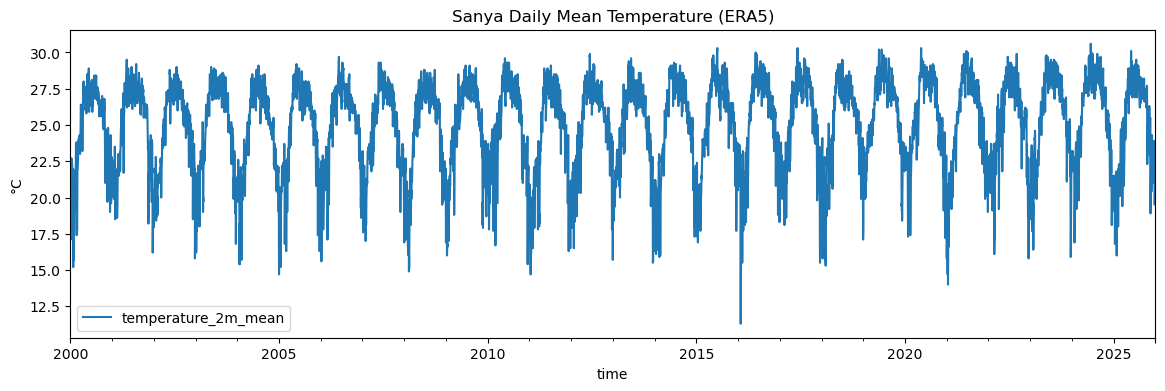

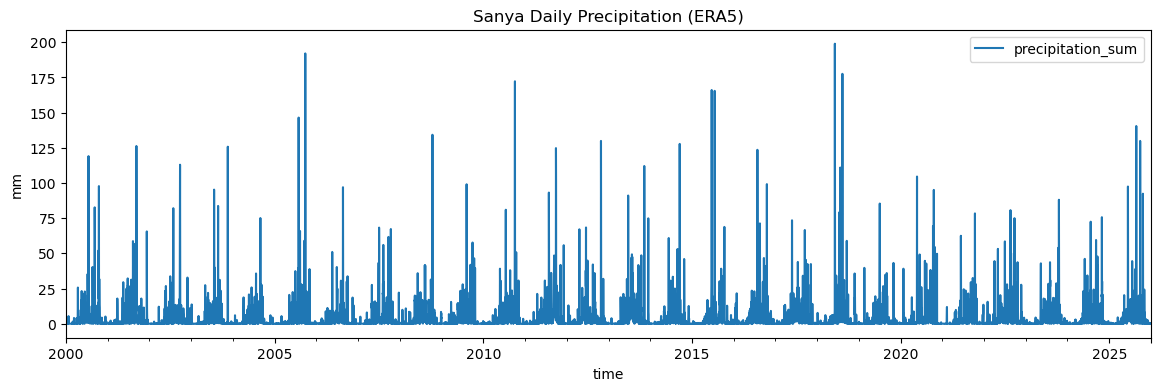

In [19]:
daily_plot = daily_raw.copy(); daily_plot["time"] = pd.to_datetime(daily_plot.time)
if "temperature_2m_mean" in daily_plot.columns:
    daily_plot.plot(x="time", y="temperature_2m_mean", figsize=(14,4), title="Sanya Daily Mean Temperature (ERA5)"); plt.ylabel("°C"); plt.show()
if "precipitation_sum" in daily_plot.columns:
    daily_plot.plot(x="time", y="precipitation_sum", figsize=(14,4), title="Sanya Daily Precipitation (ERA5)"); plt.ylabel("mm"); plt.show()

## 10. Merge with Tourist Arrivals (template only)
Adapt the tourism file and column names when the target dataset has been selected. Align monthly timestamps before joining.

In [ ]:
# Example — uncomment and adapt later:
# tourism = pd.read_csv("sanya_monthly_tourist_arrivals.csv")
# tourism["time"] = pd.to_datetime(tourism["time"])
# merged = monthly_weather.merge(tourism, on="time", how="inner")
# merged.to_csv(PROCESSED_DIR / "sanya_monthly_weather_tourism_ml.csv", index=False)
# merged.head()

## 11. Expected output structure
sanya_weather_data/

├── raw/

│   ├── sanya_daily_2000_2025.csv

│   ├── sanya_hourly_2000_2025.csv

│   ├── sanya_daily_YYYY.csv (annual checkpoints)

│   └── sanya_hourly_YYYY.csv (annual checkpoints)

└── processed/

    ├── sanya_daily_weather_ml_features.csv
    
    ├── sanya_hourly_aggregated_daily_features.csv
    
    └── sanya_monthly_weather_features.csv

Next research steps: select and collect tourist-arrival targets, merge with monthly weather, add holidays/events and transportation variables, then split chronologically into train/validation/test to avoid temporal leakage.

Source: Open-Meteo Historical Weather API documentation: https://open-meteo.com/en/docs/historical-weather-api
ERA5 is documented as hourly reanalysis from 1940 at approximately 0.25° (~25 km). Reanalysis is model-derived and should not be described as direct station observations. Check Open-Meteo attribution/license terms when publishing results.